In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# Self-employment: how large is it in Italy, where, and how do the self-employed fare?
Notebook 30 described the income distribution; the next question is **who the self-employed are**. Eurostat's labour force survey (`lfsa_esgan`, `lfsa_esgan2`, `lfsa_egan2`) gives the share of employment that is self-employed (employers and own-account workers without employees), by sector and age; EU-SILC (`ilc_li04`) gives at-risk-of-poverty rates by activity status (`NSAL` = employed persons except employees: self-employed plus contributing family workers). Table `data/processed/selfemp.parquet`, code `src/cifresignificative/studies/italy_productivity/analysis/selfemp.py`.
Method: window means (breaks `b` and provisional `p` values dropped), Italy ranked among the 27 members by a **placebo ranking** (Italy's gap to the median of the others against every country's own gap; `p_abs` = share of countries with a gap at least as large; with 27 countries the smallest possible value is 1/27 = 0.04, so 0.07 means the second largest gap), and an exact **shift-share decomposition** of the sector mix against the pooled other countries.
**What is not here:** the self-employed's *income* and the flat-rate regime (regime forfettario). Eurostat has no income by employment status; that needs the Ministry of Economy IRPEF tables (`docs/manual_data.md`). The policy dates are shown only as markers. **Descriptive only, never causal**: the share of self-employment moves with many things besides tax rules.

In [2]:
from cifresignificative.studies.italy_productivity.analysis import selfemp as SE, income_dist as ID
se = SE.load_selfemp()
S = SE.share_wide(se)
WIN = {"2005-09": (2005, 2009), "2015-19": (2015, 2019), "2021-25": (2021, 2025)}
print("rows:", len(se), "| tables:", se.groupby("table").size().to_dict())
for c, lab in [("SELF", "all self-employed"), ("SELF_NS", "own-account (no employees)"), ("SELF_S", "employers")]:
    print(lab, "- % of employment 15-64"); display(SE.window_gap(S, c, WIN).round(2))
top = ID.window_table(S, WIN["2015-19"]).SELF.sort_values(ascending=False).head(6).round(1); print("highest in 2015-19:", top.to_dict())
print("Italy's yearly series (% of employment):"); display(S.xs(ITALY, level="iso3").round(1).T)
print("Change in the own-account share, window means 2012-14 -> 2022-25, Italy vs placebo ranking:", SE.rank_in(SE.change_between(S, "SELF_NS", (2012, 2014), (2022, 2025))))
print("Change, 2005-09 -> 2015-19:", SE.rank_in(SE.change_between(S, "SELF_NS", (2005, 2009), (2015, 2019))), "| 2015-19 -> 2021-25:", SE.rank_in(SE.change_between(S, "SELF_NS", (2015, 2019), (2021, 2025))))

rows: 28592 | tables: {'arop_by_status': 1278, 'employed_nace_ths': 11122, 'selfemp_nace_ths': 8393, 'selfemp_share_age': 2372, 'selfemp_share_status': 5427}
all self-employed - % of employment 15-64


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,23.12,12.58,10.55,2,27,0.07
1,2015-19,21.15,11.91,9.24,2,27,0.07
2,2021-25,19.38,11.61,7.76,2,27,0.07


own-account (no employees) - % of employment 15-64


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,16.48,8.91,7.56,3,27,0.11
1,2015-19,15.25,8.39,6.86,2,27,0.07
2,2021-25,13.12,7.91,5.21,3,27,0.11


employers - % of employment 15-64


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,6.68,3.98,2.70,2,27,0.07
1,2015-19,5.92,3.88,2.05,2,27,0.11
2,2021-25,6.28,3.62,2.65,2,27,0.07


highest in 2015-19: {'GRC': 29.2, 'ITA': 21.2, 'POL': 17.6, 'ROU': 16.2, 'CZE': 16.1, 'ESP': 15.7}
Italy's yearly series (% of employment):


year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2019,2020,2022,2023,2024,2025
wstatus,,,,,,,,,,,,,,,,,,
SELF,23.7,23.4,22.9,22.5,22.8,22.6,22.5,22.4,22.2,21.9,21.5,20.8,20.4,20.2,19.5,19.3,19.1,19.6
SELF_NS,16.9,16.7,16.2,16.1,16.4,16.2,16.2,15.8,16.0,15.7,15.4,15.1,14.8,14.7,13.7,13.4,12.8,12.6
SELF_S,6.8,6.8,6.6,6.5,6.4,6.4,6.3,6.6,6.2,6.2,6.1,5.8,5.6,5.6,5.8,5.8,6.4,7.1


Change in the own-account share, window means 2012-14 -> 2022-25, Italy vs placebo ranking: {'value': -2.875, 'rank_from_top': 22, 'n_countries': 27, 'p_abs': 0.2222222222222222}
Change, 2005-09 -> 2015-19: {'value': -1.2250000000000014, 'rank_from_top': 22, 'n_countries': 27, 'p_abs': 0.48148148148148145} | 2015-19 -> 2021-25: {'value': -2.125, 'rank_from_top': 24, 'n_countries': 27, 'p_abs': 0.18518518518518517}


In [3]:
rows = []
for y in (2010, 2019, 2024):
    F = SE.sector_frame(se, y); D = SE.decompose_all(F); d = SE.decompose(F)
    rows.append({"year": y, "countries": len(F), "Italy share %": d["share"], "pooled others %": d["pooled_others"], "gap pp": d["share"] - d["pooled_others"], "composition pp": d["composition"], "within-sector pp": d["within_sector"],
                 "rank within (1 = largest)": SE.rank_in(D.within_sector)["rank_from_top"], "p_abs within": SE.rank_in(D.within_sector)["p_abs"], "rank composition": SE.rank_in(D.composition)["rank_from_top"], "p_abs composition": SE.rank_in(D.composition)["p_abs"]})
display(pd.DataFrame(rows).round(2).set_index("year"))
F = SE.sector_frame(se, 2019); it = F.loc[ITALY]; oth = F.drop(ITALY)
sect = pd.DataFrame({"Italy rate %": it["self"] / it["emp"] * 100, "others rate %": oth["self"].sum() / oth["emp"].sum() * 100, "Italy employment weight %": it["emp"] / it["emp"].sum() * 100, "others weight %": oth["emp"].sum() / oth["emp"].to_numpy().sum() * 100})
sect["contribution to the within-sector gap, pp"] = sect["Italy employment weight %"] / 100 * (sect["Italy rate %"] - sect["others rate %"])
print("2019, by NACE section (countries with complete data: %d)" % len(F)); display(sect.round(1).sort_values("contribution to the within-sector gap, pp", ascending=False))
A = SE.age_wide(se)
for a in ("Y15-24", "Y25-49", "Y50-64"): print("age", a, "-> self-employed % of employment in the band"); display(SE.window_gap(A, a, WIN).round(2))

,countries,Italy share %,pooled others %,gap pp,composition pp,within-sector pp,rank within (1 = largest),p_abs within,rank composition,p_abs composition
year,,,,,,,,,,
2010,19,23.32,13.45,9.88,0.46,9.42,2,0.11,9,0.89
2019,21,21.03,12.15,8.87,0.53,8.34,2,0.10,10,0.67
2024,21,19.56,12.15,7.41,0.57,6.84,2,0.10,6,0.38


2019, by NACE section (countries with complete data: 21)


,Italy rate %,others rate %,Italy employment weight %,others weight %,"contribution to the within-sector gap, pp"
nace_r2,,,,,
G,31.6,13.7,14.5,14.0,2.6
M,57.0,26.0,6.6,5.5,2.1
F,35.9,21.1,6.0,7.0,0.9
C,9.0,5.0,19.4,16.3,0.8
Q,14.6,7.8,8.4,11.4,0.6
I,23.6,14.4,6.5,4.8,0.6
S,36.8,27.5,3.1,2.4,0.3
L,48.0,21.4,0.7,0.8,0.2
R,38.5,21.2,1.4,1.7,0.2


age Y15-24 -> self-employed % of employment in the band


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,10.60,3.84,6.76,2,25,0.08
1,2015-19,10.20,3.64,6.56,2,27,0.07
2,2021-25,9.12,4.06,5.06,3,24,0.12


age Y25-49 -> self-employed % of employment in the band


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,22.75,12.11,10.64,2,27,0.07
1,2015-19,20.50,11.33,9.17,2,27,0.07
2,2021-25,18.12,11.45,6.68,2,27,0.07


age Y50-64 -> self-employed % of employment in the band


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2005-09,27.92,16.98,10.95,4,27,0.15
1,2015-19,23.80,16.14,7.66,2,27,0.07
2,2021-25,22.55,14.45,8.10,2,27,0.07


In [4]:
P = SE.poverty_wide(se)
PW = {"2015-19": (2015, 2019), "2021-25": (2021, 2025)}
for c, lab in [("NSAL", "at-risk-of-poverty rate, employed except employees (self-employed and family workers), %"), ("SAL", "employees, %"), ("gap_nsal_sal", "gap NSAL minus SAL, pp"), ("ratio_nsal_sal", "ratio NSAL / SAL")]:
    print(lab); display(SE.window_gap(P, c, PW).round(2))
print("countries with the rate:", P.NSAL.groupby(level="iso3").count().gt(0).sum(), "| first year:", P.NSAL.dropna().index.get_level_values("year").min())

at-risk-of-poverty rate, employed except employees (self-employed and family workers), %


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2015-19,18.74,17.68,1.06,13,27,0.96
1,2021-25,17.62,15.82,1.80,10,27,0.67


employees, %


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2015-19,10.06,6.05,4.01,3,27,0.15
1,2021-25,8.90,6.28,2.62,4,27,0.33


gap NSAL minus SAL, pp


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2015-19,8.68,12.03,-3.35,19,27,0.59
1,2021-25,8.72,9.86,-1.14,16,27,0.85


ratio NSAL / SAL


,window,value,median_others,gap,rank_from_top,n_countries,p_abs
0,2015-19,1.88,3.05,-1.17,23,27,0.44
1,2021-25,2.00,2.91,-0.91,23,27,0.48


countries with the rate: 27 | first year: 2009


,date,title,reference,evidence
28,2019-01-01,"Regime forfettario threshold raised to EUR 65,000",L. 145/2018 (budget law 2019); regime created ...,verified


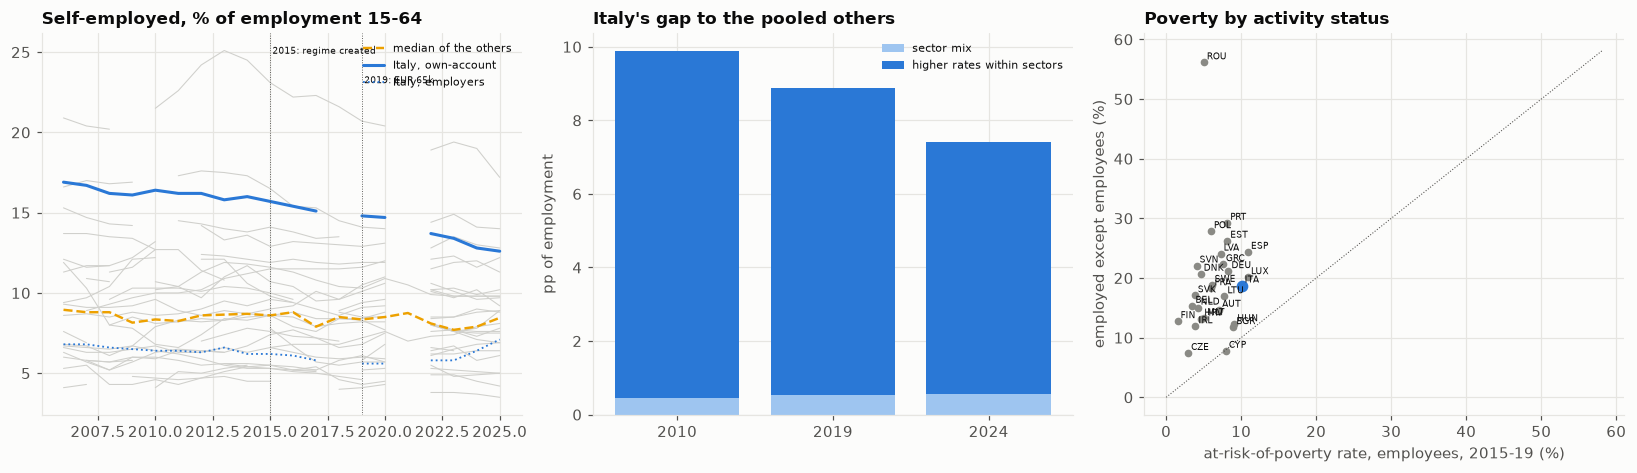

In [5]:
pol = pd.read_csv("data/external/italy_policies.csv", parse_dates=["date"]); fr = pol[pol.title.str.contains("forfettario", case=False)][["date", "title", "reference", "evidence"]]
display(fr)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]; z = S.SELF_NS.unstack("iso3")
for c in z: ax.plot(z.index, z[c], color="#d0d0cc", lw=0.7)
ax.plot(z.index, z.drop(columns=ITALY).median(axis=1), color="#eda100", ls="--", lw=1.6, label="median of the others"); ax.plot(z.index, z[ITALY], color=ITALY_C, lw=2, label="Italy, own-account")
zs = S.SELF_S.unstack("iso3"); ax.plot(zs.index, zs[ITALY], color=ITALY_C, lw=1.2, ls=":", label="Italy, employers")
ax.axvline(2015, color=INK2, lw=0.6, ls=":"); ax.axvline(2019, color=INK2, lw=0.6, ls=":"); ax.text(2015.1, ax.get_ylim()[1] * 0.97, "2015: regime created", fontsize=6, va="top"); ax.text(2019.1, ax.get_ylim()[1] * 0.9, "2019: EUR 65k", fontsize=6, va="top")
ax.set_title("Self-employed, % of employment 15-64"); ax.legend(fontsize=7)
ax = axes[1]; d = pd.DataFrame(rows).set_index("year")
ax.bar(range(len(d)), d["composition pp"], color="#9ec5f0", label="sector mix"); ax.bar(range(len(d)), d["within-sector pp"], bottom=d["composition pp"], color=ITALY_C, label="higher rates within sectors")
ax.set_xticks(range(len(d)), d.index); ax.set_ylabel("pp of employment"); ax.set_title("Italy's gap to the pooled others"); ax.legend(fontsize=7)
ax = axes[2]; T = ID.window_table(P, PW["2015-19"]).dropna(subset=["NSAL", "SAL"])
for c in T.index: ax.scatter(T.loc[c, "SAL"], T.loc[c, "NSAL"], color=ITALY_C if c == ITALY else "#8a8a85", s=44 if c == ITALY else 16, zorder=3 if c == ITALY else 2); ax.annotate(c, (T.loc[c, "SAL"], T.loc[c, "NSAL"]), fontsize=6, xytext=(2, 2), textcoords="offset points")
lim = [0, max(T.NSAL.max(), T.SAL.max()) + 2]; ax.plot(lim, lim, color=INK2, lw=0.7, ls=":"); ax.set_xlabel("at-risk-of-poverty rate, employees, 2015-19 (%)"); ax.set_ylabel("employed except employees (%)"); ax.set_title("Poverty by activity status")
fig.tight_layout(); save(fig, "31_self_employment")

## Takeaways (EU labour force survey and EU-SILC via Eurostat, 2005-2025; descriptive, cross-country)
- **Italy has the second-highest self-employment share in the EU27, after Greece.** Self-employed persons were 23.1% of employment aged 15-64 in 2005-09, 21.2% in 2015-19 (Greece 29.2%, Poland 17.6%, Romania 16.2%) and 19.4% in 2021-25, against medians of the others of 12.6%, 11.9% and 11.6%: a gap of 10.6, 9.2 and 7.8 pp, 2nd of 27 in every window (`p_abs` 0.07, the second-smallest value possible). The gap is not mainly employers: own-account workers without employees are 16.5%, 15.3% and 13.1% (others 8.9%, 8.4%, 7.9%; 3rd, 2nd, 3rd), employers 6.7%, 5.9% and 6.3% (others 4.0%, 3.9%, 3.6%). Italy's yearly series lacks 2005, 2018 and 2021 because those values carry a break flag and are dropped.
- **It is shrinking, at a pace that is ordinary.** From 2012-14 to 2022-25 the own-account share fell 2.9 pp (16.0% in 2014 to 12.6% in 2025) against a median change of -0.2 pp for the others; Italy is 22nd of 27 from the top (`p_abs` 0.22), with Romania (-7.7), Greece (-6.0), Croatia (-4.9) and Cyprus (-3.4) falling more. Windows 2005-09 -> 2015-19 (-1.2 pp, rank 22, `p_abs` 0.48) and 2015-19 -> 2021-25 (-2.1 pp, rank 24, `p_abs` 0.19) are no different. No break in the series stands out around 2015 (regime created) or 2019 (threshold raised to EUR 65,000) in the aggregate share; the aggregate cannot show behaviour just below a threshold, and the survey counts people, not tax regimes.
- **Within sectors, not sector mix.** Against the pooled other countries, Italy's 2019 gap of 8.9 pp splits into 0.5 pp from the sector mix (the weights; Italy's composition ranks 10th of 21, `p_abs` 0.67) and 8.3 pp from higher self-employment rates inside the same sectors (2nd of 21, `p_abs` 0.10). The same holds in 2010 (9.4 of 9.9 pp within) and 2024 (6.8 of 7.4). The largest contributions to the within-sector part come from wholesale and retail trade (2.6 pp; 31.6% of workers self-employed against 13.7%), professional and scientific activities (2.1 pp; 57.0% against 26.0%), construction (0.9 pp), manufacturing (0.8 pp), health and social work, and accommodation and food (0.6 pp each); agriculture goes the other way (-0.6 pp: 37.6% against 52.4%). Only the 21 countries with complete sector tables enter (Eurostat leaves out small cells, which are set to zero when the totals add up to at least 97%).
- **At every age band.** The self-employed share is higher than the median of the others by 6.6 pp at 15-24 (10.2% against 3.6%, 2015-19), 9.2 pp at 25-49 and 7.7 pp at 50-64 (2nd of 27 in each); the gap has narrowed in the youngest band (5.1 pp in 2021-25) and at 25-49 (6.7 pp), not at 50-64 (8.1 pp).
- **Poverty: the self-employed are not unusually poor *relative to other countries*, the employees are.** At-risk-of-poverty rate (60% of the median, 18-64) of employed persons other than employees (mostly self-employed): 18.7% in 2015-19 and 17.6% in 2021-25, close to the median of the others (17.7% and 15.8%; ranks 13th and 10th of 27, `p_abs` 0.96 and 0.67). Employees are the unusual group: 10.1% against 6.1% (3rd highest of 27, `p_abs` 0.15) and 8.9% against 6.3% in 2021-25 (4th). The self-employed-to-employee ratio is 1.9 and 2.0, below the median of the others (3.0 and 2.9; 23rd of 27 both times) and the gap 8.7 pp against 12.0 and 9.9, so in Italy the self-employed are about as poor as elsewhere but employees are poorer than elsewhere. Several countries have more contributing family workers in this category, so it is not a clean self-employed rate.
- **Limits.** Counts of people, not income: the survey says nothing on declared income or the flat-rate regime, which needs the MEF IRPEF tables (manual download; open). Break flags remove some Italian years. The poverty comparison uses an activity-status definition (`NSAL`) that includes family workers and the previous year's main activity; sample sizes of self-employed groups are small in several countries. The 2015 date of the regime's creation (L. 190/2014) is taken from the reference in `italy_policies.csv`, not separately verified. Everything is descriptive: shares move with sector structure, tax rules, labour regulation and the cycle together.
